# Grover's Algorithm for Satisfiability Problems

*Quantum Computing - MSc in Engineering Physics (Physics of Information), University of Minho. Gabriel A. Pedrosa (pg56212).*

Grover's algorithm offers a quadratic speedup for unstructured search. Satisfiability problems, where the goal is to find an assignment of variables that satisfies a logical formula, are a natural target: the space of candidate assignments carries no structure to exploit, so a classical approach can do little better than test the assignments one by one. The following sections apply Grover to two such problems, a boolean formula and a 2x2 binary Sudoku, extend the Sudoku construction to larger boards, and finally test the circuits under noise and on IBM hardware. The reusable building blocks live in the `grover_sat` module; the emphasis here is on the reasoning behind each step.

## 1. Satisfiability problems

A satisfiability problem asks whether there exists an assignment of truth values to a set of variables that makes a given logical formula true. Boolean satisfiability (SAT) is the canonical example and is foundational in computational theory, with applications in optimization, cryptography and artificial intelligence.

A formula over $n$ variables admits $2^n$ possible assignments, so deciding satisfiability by exhaustive search costs $O(2^n)$ in the worst case. Grover's algorithm reduces this to $O(\sqrt{2^n / M})$, where $M$ is the number of satisfying assignments.

## 2. Grover's algorithm

Grover's algorithm searches a space of $N = 2^n$ candidate states, of which $M$ are marked as solutions, by amplifying the amplitude of the marked states. Each iteration applies two operators:

- an **oracle**, which flips the phase of the solution states;
- a **diffuser**, which reflects every amplitude about their mean.

Geometrically the pair performs a rotation in the plane spanned by the solutions and the non-solutions, turning the state towards the solution subspace. With $\theta = \arcsin\sqrt{M/N}$, the probability of measuring a solution after $k$ iterations is

$$P(k) = \sin^2\big((2k+1)\,\theta\big),$$

which is maximised near $k \approx \frac{\pi}{4}\sqrt{N/M}$. This estimate assumes $M \ll N$; when solutions are abundant the optimal $k$ must be chosen with more care, as Section 3 illustrates.

The oracles below rely on *phase kickback*. An ancilla qubit is prepared in $|-\rangle$ and the oracle flips it whenever the current assignment is a solution. Since $X|-\rangle = -|-\rangle$, that flip turns into a $-1$ phase on the solution, precisely the marking the diffuser expects.

In [18]:
import sys, os
for p in (".", ".."):
    if os.path.isdir(os.path.join(p, "grover_sat")):
        sys.path.insert(0, os.path.abspath(p))
        break

%matplotlib inline
import matplotlib.pyplot as plt

from grover_sat import (
    solve_cnf, solve_dnf, cnf_solutions, dnf_solutions,
    solve_sudoku, decode_board, board_grid,
    plot_probs, top_states, n_iterations,
)

## 3. A 3-SAT problem

Consider the formula

$$F = (A \land \lnot B)\ \lor\ (A \land C)\ \lor\ (\lnot A \land B \land \lnot C)\ \lor\ (C \land \lnot B),$$

obtained by reducing the original clauses to disjunctive normal form (a disjunction of conjunctions). The task is to find the assignments of $A, B, C$ that make $F$ true. With only three variables the solutions could be found by hand, but the exercise is to recover them with Grover, without assuming them in advance.

The formula combines ANDs and ORs. Conjunctions map directly onto multi-controlled-X gates, with Pauli-X gates acting as negation, while disjunctions are less immediate. De Morgan's law removes the difficulty,

$$A \lor B \lor \cdots = \lnot(\lnot A \land \lnot B \land \cdots),$$

so an OR becomes the negated AND of the negated terms. Each conjunctive term is computed onto its own auxiliary qubit, and a final multi-controlled-X with negated inputs flips the ancilla whenever at least one term holds. The auxiliary qubits are then uncomputed by repeating their construction, which is possible because the gates involved are their own inverse.

satisfying assignments: [1, 2, 4, 5, 7]
  001 0.195
  010 0.195
  101 0.195
  111 0.195
  100 0.195


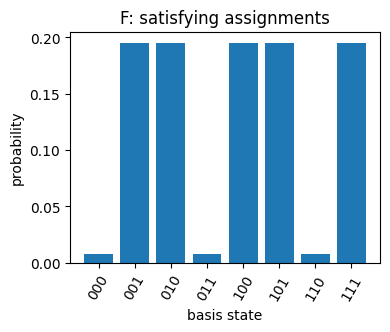

In [19]:
# DIMACS-style literals: 1, 2, 3 are A, B, C; a minus sign negates.
# F = (A & ~B) | (A & C) | (~A & B & ~C) | (C & ~B)
F = [[1, -2], [1, 3], [-1, 2, -3], [3, -2]]

print('satisfying assignments:', dnf_solutions(F, 3))

probs = solve_dnf(F, 3, iters=2)
for state, p in top_states(probs, 3):
    print(' ', state, round(p, 3))

plot_probs(probs, 3, title='F: satisfying assignments')
plt.show()

The five amplified states are exactly the rows of the truth table of $F$ that evaluate to true, each measured with probability close to $0.2$ and summing to almost $1$.

### 3.1 The number of iterations

The choice of two iterations deserves a comment. Here $N = 2^3 = 8$ and $M = 5$, so more than half of the states are solutions. The closed-form estimate $k \approx \frac{\pi}{4}\sqrt{N/M} \approx 1$ assumes $M \ll N$ and is misleading here. The success probability must instead be read from $P(k) = \sin^2((2k+1)\theta)$ with $\theta = \arcsin\sqrt{5/8} \approx 0.912$:

- $k = 1$: $P = \sin^2(3\theta) \approx 0.16$, which ends up amplifying the non-solutions;
- $k = 2$: $P = \sin^2(5\theta) \approx 0.98$, very close to ideal.

When the analytic estimate is unreliable, a short scan over small $k$ settles the question.

In [20]:
N, M = 8, len(dnf_solutions(F, 3))
print('closed-form estimate:', n_iterations(N, M))
for k in range(1, 5):
    p = solve_dnf(F, 3, iters=k)
    hit = sum(p[i] for i in dnf_solutions(F, 3))
    print(f'  k = {k}:  P(solution) = {hit:.3f}')

closed-form estimate: 1
  k = 1:  P(solution) = 0.156
  k = 2:  P(solution) = 0.977
  k = 3:  P(solution) = 0.010
  k = 4:  P(solution) = 0.881


### 3.2 The conjunctive form

SAT instances are usually stated in conjunctive normal form (a conjunction of clauses, each a disjunction of literals). The same machinery applies with the roles of AND and OR exchanged: every clause is computed onto an auxiliary qubit and the ancilla is flipped only when all clauses hold simultaneously. This is exposed as `solve_cnf`.

satisfying assignments: [2, 3, 4, 5, 7]


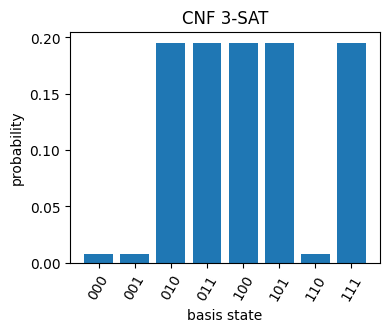

In [21]:
# (x0 | x1 | ~x2) & (~x0 | ~x1 | x2) & (x0 | x1 | x2)
clauses = [[1, 2, -3], [-1, -2, 3], [1, 2, 3]]
print('satisfying assignments:', cnf_solutions(clauses, 3))

plot_probs(solve_cnf(clauses, 3, iters=2), 3, title='CNF 3-SAT')
plt.show()

## 4. A 2x2 binary Sudoku

A 2x2 binary Sudoku is defined by three rules:

1. no row may contain the same value twice;
2. no column may contain the same value twice;
3. the entries are binary.

Each of the four cells is assigned one qubit, with $|0\rangle$ and $|1\rangle$ standing for the two symbols. Reading the qubits top to bottom and left to right, the state $|1001\rangle$ encodes the board with first row $1\,0$ and second row $0\,1$, which is a valid solution.

### 4.1 The oracle

For binary cells, the requirement that two cells differ is just their exclusive OR: two CNOTs write $a \oplus b$ onto an auxiliary qubit, which becomes $1$ exactly when the cells disagree. One auxiliary qubit is used per constraint (the distinct pairs within each row and each column), and a multi-controlled-X then flips the ancilla only when all constraints hold at once. The auxiliary qubits are uncomputed afterwards, so the oracle may be applied repeatedly, and the diffuser follows the standard design without noteworthy modifications. The oracle is built as though the solution were unknown, even though for a board this small it is not.

  0110 -> [[0, 1], [1, 0]] 0.473
  1001 -> [[1, 0], [0, 1]] 0.473


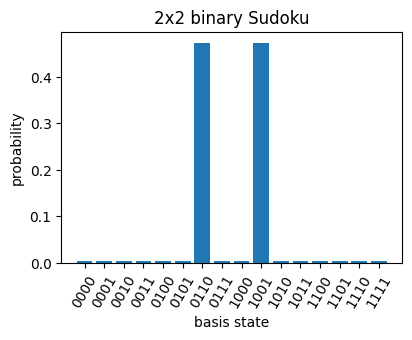

In [22]:
probs = solve_sudoku(2, values=2)
for state, p in top_states(probs, 4):
    board = board_grid(decode_board(int(state, 2), 2, 2), 2)
    print(' ', state, '->', board, round(p, 3))

plot_probs(probs, 4, title='2x2 binary Sudoku')
plt.show()

The states `0110` and `1001` are the only valid 2x2 binary Sudokus, each recovered with probability close to $0.5$.

### 4.2 A revealed cell

It is more common than not, in Sudoku, to know some of the entries in advance. A known cell need not be searched over: its qubit is fixed to the known value and kept out of both the initial superposition and the diffuser, which shrinks the search space. Revealing the top-left cell as $0$ leaves a single valid completion.

unique solution: [[0, 1], [1, 0]] with probability 0.945


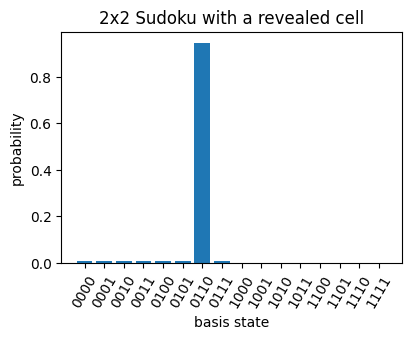

In [23]:
probs = solve_sudoku(2, values=2, givens={0: 0})
state, p = top_states(probs, 4)[0]
print('unique solution:', board_grid(decode_board(int(state, 2), 2, 2), 2),
      'with probability', round(p, 3))

plot_probs(probs, 4, title='2x2 Sudoku with a revealed cell')
plt.show()

### 4.3 Complexity

A classical brute force tests all $2^n$ assignments in the worst case, for a cost of $O(2^n)$. Grover finds a valid board in $O(\sqrt{2^n / M})$ iterations; for the 2x2 board $M = 2$, which gives $O(\sqrt{2^{\,n-1}})$.

## 5. Larger boards

A single qubit only stores a binary value, so a board with more than two symbols per cell requires more than one qubit per cell. Two encodings were considered in the report:

- **one-hot encoding**, with one qubit per possible symbol, which is wasteful (a standard 9x9 board would demand nine qubits per cell);
- **two-bit encoding**, with $\lceil \log_2 v \rceil$ qubits per cell for $v$ symbols, which scales considerably better.

The module adopts the second. When $v$ is not a power of two, some bit patterns correspond to no symbol (for three symbols, the pattern $11$), and the oracle marks those as invalid so they are never amplified. Rows, columns and, optionally, sub-boxes supply the distinctness constraints automatically.

In [24]:
# three symbols per cell -> 2 qubits/cell; the pattern 11 (=3) is invalid
probs = solve_sudoku(2, values=3)
boards = [decode_board(int(s, 2), 2, 3) for s, _ in top_states(probs, 8)]
print('number of valid boards found:', len(boards))
print('any cell using the invalid value 3?', any(3 in b for b in boards))
print('examples:', [board_grid(b, 2) for b in boards[:3]])

number of valid boards found: 18
any cell using the invalid value 3? False
examples: [[[0, 1], [1, 2]], [[0, 2], [1, 0]], [[1, 0], [0, 1]]]


The cost of generality is the qubit count: the board qubits, plus one auxiliary per constraint, plus an ancilla. It grows quickly, so only small boards fit in a state-vector simulator. A few representative sizes follow.

In [25]:
from grover_sat.sudoku import distinct_pairs, cell_bits

for n, v, box in [(2, 2, None), (2, 3, None), (2, 4, None),
                  (3, 3, None), (4, 4, (2, 2))]:
    bits = cell_bits(v)
    flags = len(distinct_pairs(n, box)) + (n * n) * (2 ** bits - v)
    scratch = bits if bits > 1 else 0
    total = n * n * bits + flags + scratch + 1
    print(f'n={n}, values={v}, box={box}: {total} qubits')

n=2, values=2, box=None: 9 qubits
n=2, values=3, box=None: 19 qubits
n=2, values=4, box=None: 15 qubits
n=3, values=3, box=None: 48 qubits
n=4, values=4, box=(2, 2): 91 qubits


### The circuit

Because the oracle is generated from the problem description, the resulting circuit can be inspected directly. A single Grover iteration of the 2x2 binary Sudoku is shown below: wires 0-3 hold the board, wires 4-7 hold the constraint flags produced by the CNOT pairs, and wire 8 is the ancilla. The diffuser is the final block acting on the board qubits.

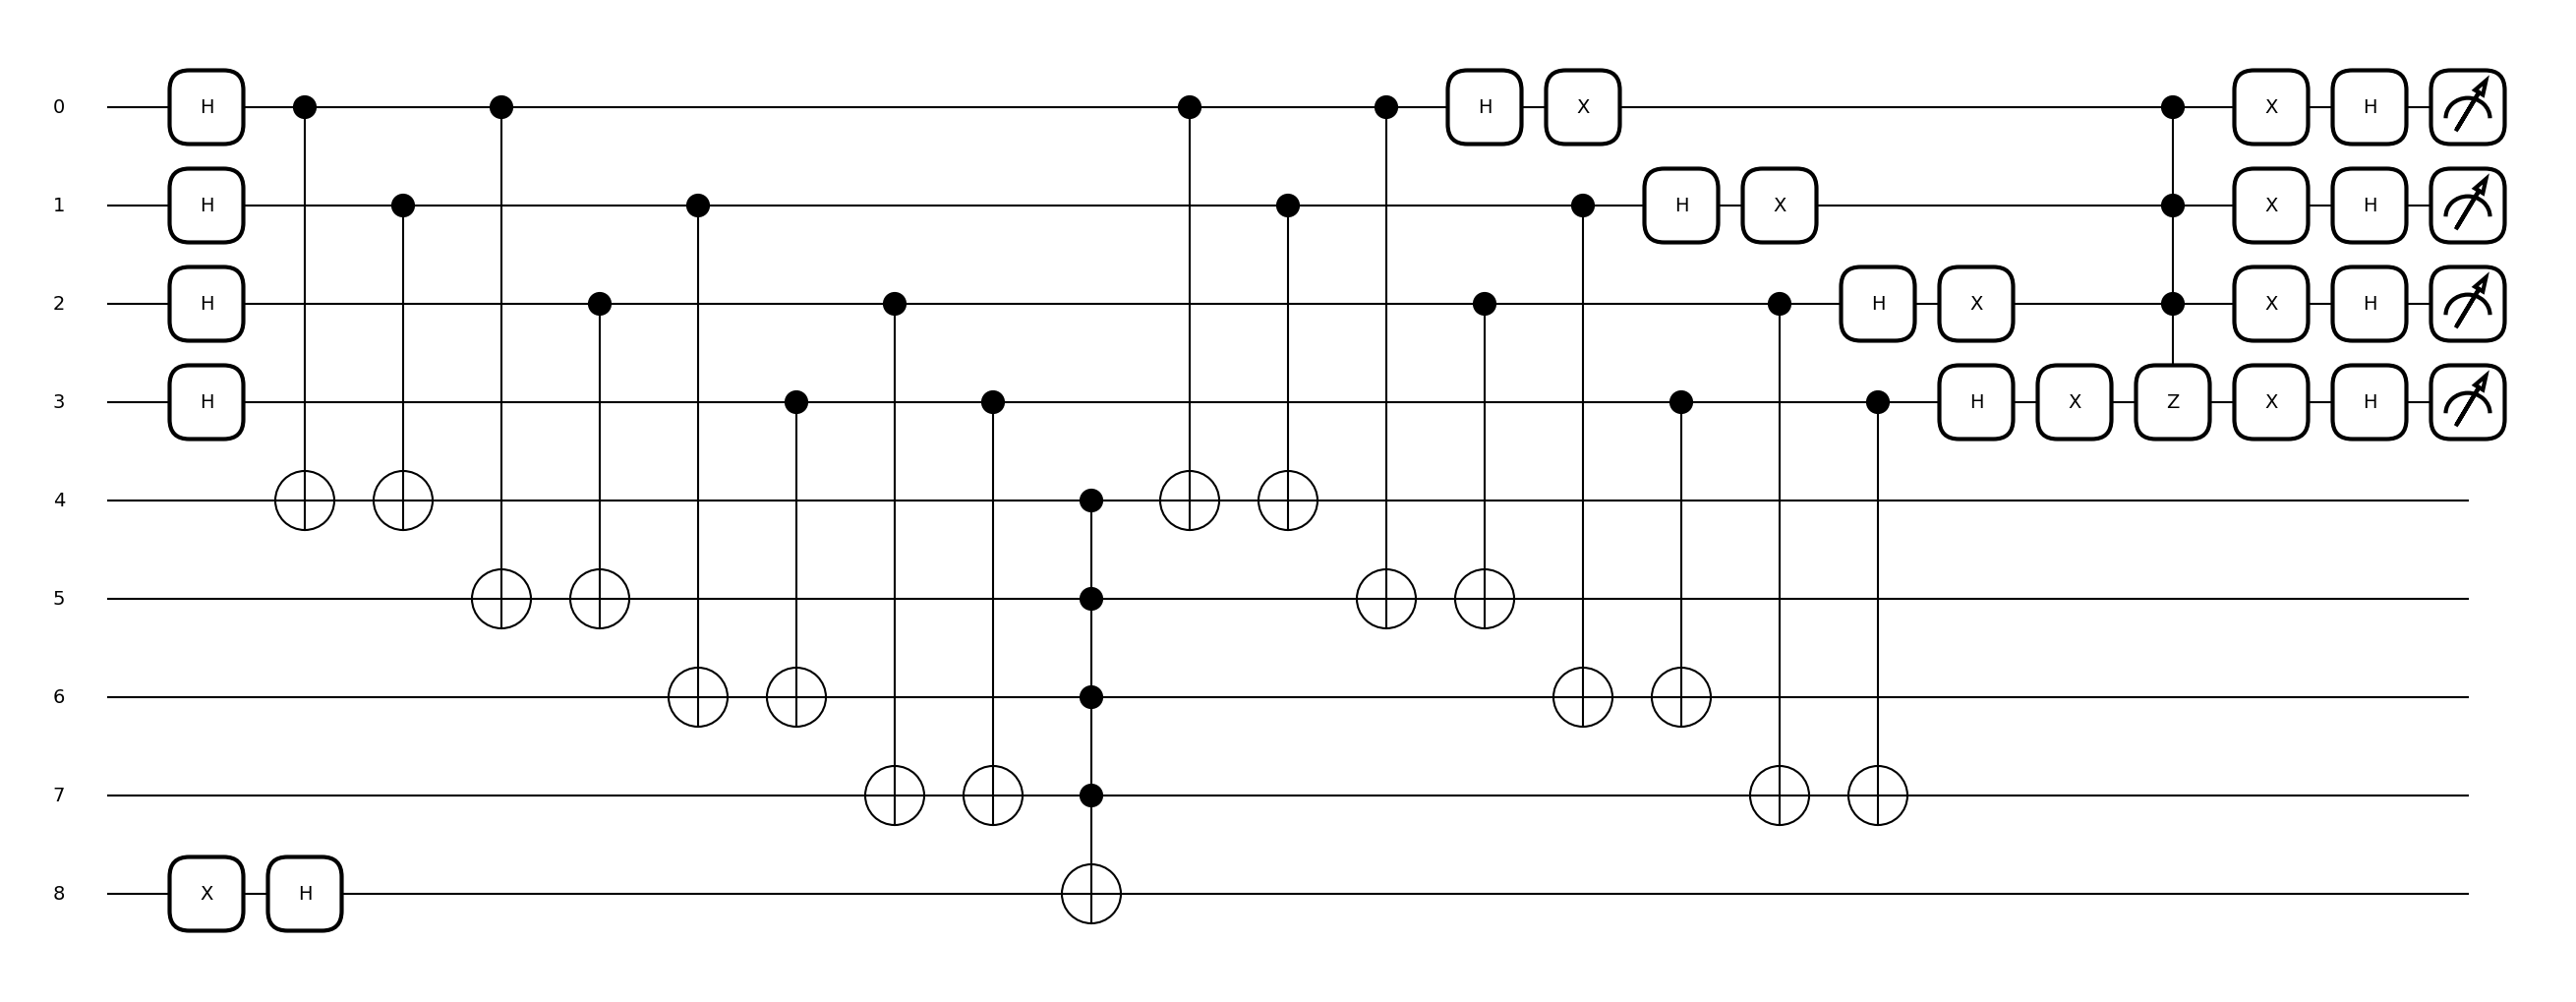

In [26]:
fig, ax = solve_sudoku(2, values=2, iters=1, draw=True)
plt.show()

## 6. Towards real hardware: noise and error mitigation

Every result so far comes from an ideal, noiseless simulator. Real quantum devices suffer from gate errors, decoherence and readout errors, all of which degrade the interference Grover's algorithm relies on. This section identifies which circuit is worth running on a real device, runs it (code ready for an IBM backend), and applies error mitigation to recover part of the lost signal.

### 6.1 Choosing a circuit the hardware can handle

The 2x2 Sudoku circuit is a poor candidate for current hardware. Its oracle and diffuser use multi-controlled gates that, once transpiled to a device's native two-qubit gates and limited connectivity, expand into a large number of CNOTs across nine qubits, repeated over several Grover iterations. At today's error rates the accumulated noise leaves an essentially uniform output, with no peak left for mitigation to recover: error mitigation only helps when part of the ideal signal survives.

A better demonstration is the smallest non-trivial Grover instance: searching three qubits for a single marked bit string, which is the same as a 3-SAT instance with a unique solution. A *phase oracle* marks the target directly with a multi-controlled Z, so no ancilla or work qubits are required and the circuit stays shallow. With $N = 8$ and $M = 1$, two iterations reach a success probability of $\sin^2(5\theta) \approx 0.95$.

ideal P(101) = 0.945


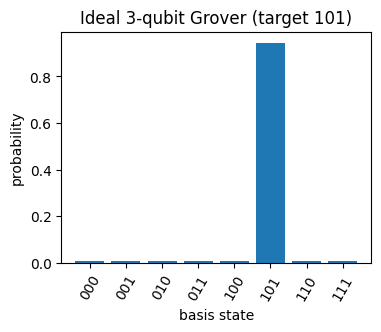

In [27]:
import pennylane as qml
import numpy as np
from grover_sat.grover import diffuser
from pennylane import mitigate_with_zne, fold_global, richardson_extrapolate

WIRES = [0, 1, 2]
TARGET = '101'
ITERS = 2
target_bits = [int(b) for b in TARGET]
target_idx = int(TARGET, 2)

def oracle():
    for w, b in zip(WIRES, target_bits):
        if b == 0:
            qml.PauliX(w)
    qml.ctrl(qml.PauliZ(WIRES[-1]), control=WIRES[:-1])
    for w, b in zip(WIRES, target_bits):
        if b == 0:
            qml.PauliX(w)

def grover_body():
    for w in WIRES:
        qml.Hadamard(w)
    for _ in range(ITERS):
        oracle()
        diffuser(WIRES)

proj = np.zeros((8, 8))
proj[target_idx, target_idx] = 1.0
target_obs = qml.Hermitian(proj, wires=WIRES)

ideal_dev = qml.device('default.qubit', wires=3)
@qml.qnode(ideal_dev)
def ideal_probs():
    grover_body()
    return qml.probs(wires=WIRES)
@qml.qnode(ideal_dev)
def ideal_expval():
    grover_body()
    return qml.expval(target_obs)

ideal_p = float(ideal_expval())
print(f'ideal P({TARGET}) = {ideal_p:.3f}')
plot_probs(ideal_probs(), 3, title=f'Ideal 3-qubit Grover (target {TARGET})')
plt.show()

### 6.2 Mitigation on a noise model

Without hardware access the same pipeline runs on the mixed-state simulator `default.mixed` with a noise model standing in for the device: a depolarizing channel on every qubit a gate touches, heavier for entangling gates. Zero-noise extrapolation (ZNE) folds each gate as $G \to G\,G^{\dagger}\,G$, which is logically the same operation but noisier, evaluates the success probability at several noise scale factors and extrapolates back to zero noise.

ideal  P(101) = 0.945
noisy  P(101) = 0.644
ZNE    P(101) = 0.899


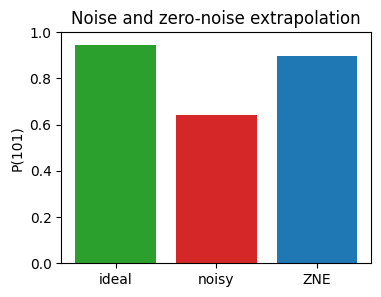

In [28]:
def add_noise_op(op, **kwargs):
    p = 0.03 if len(op.wires) >= 2 else 0.005
    for w in op.wires:
        qml.DepolarizingChannel(p, wires=w)

is_gate = qml.BooleanFn(lambda op: op.name != 'DepolarizingChannel')
noise_model = qml.NoiseModel({is_gate: add_noise_op})

noisy_dev = qml.add_noise(qml.device('default.mixed', wires=3), noise_model)
@qml.qnode(noisy_dev)
def noisy_expval():
    grover_body()
    return qml.expval(target_obs)

noisy_p = float(noisy_expval())
mitigated = mitigate_with_zne(noisy_expval, [1, 2, 3], fold_global,
                              richardson_extrapolate)
mitig_p = float(mitigated())

print(f'ideal  P({TARGET}) = {ideal_p:.3f}')
print(f'noisy  P({TARGET}) = {noisy_p:.3f}')
print(f'ZNE    P({TARGET}) = {mitig_p:.3f}')

plt.figure(figsize=(4, 3))
plt.bar(['ideal', 'noisy', 'ZNE'], [ideal_p, noisy_p, mitig_p],
        color=['tab:green', 'tab:red', 'tab:blue'])
plt.ylabel(f'P({TARGET})')
plt.ylim(0, 1)
plt.title('Noise and zero-noise extrapolation')
plt.show()

### 6.3 Trying the 2x2 Sudoku on real hardware

To test the limit described in 6.1, the 2x2 Sudoku was run on `ibm_fez` anyway. Nine connected qubits with low readout and CZ errors were chosen from the device's calibration data, and the circuit was transpiled at `optimization_level=3` with that initial layout to keep the routing overhead down. The stored outputs come from that run. To repeat it, set `RUN_ON_HARDWARE = True` and export `IBM_TOKEN`.

most frequent outcomes:
  0000: 0.087
  0010: 0.080
  1000: 0.079
  0001: 0.071
  0100: 0.070
  0110: 0.070  <- solution

P(valid)  raw hardware  = 0.124
P(valid)  ZNE-mitigated = 0.129


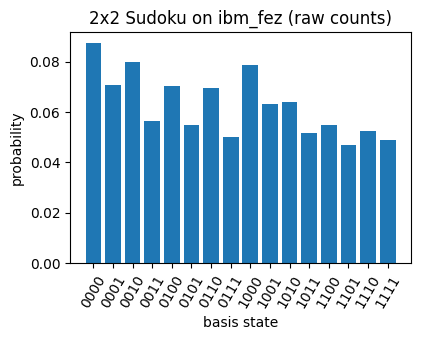

In [34]:
import os
import numpy as np
import pennylane as qml
from pennylane import mitigate_with_zne, fold_global, richardson_extrapolate
from grover_sat.grover import hadamards, diffuser, not_equal, mark_and

RUN_ON_HARDWARE = False

# board 0-3, flags 4-7, ancilla 8
BOARD, FLAGS, ANC = [0, 1, 2, 3], [4, 5, 6, 7], 8
PAIRS = [(0, 1), (0, 2), (1, 3), (2, 3)]
SOLUTIONS = ['0110', '1001']
SUDOKU_ITERS = 2

def sudoku_oracle():
    for (a, b), f in zip(PAIRS, FLAGS):
        not_equal([a], [b], f, [])
    mark_and(FLAGS, ANC)
    for (a, b), f in zip(PAIRS, FLAGS):
        not_equal([a], [b], f, [])

def sudoku_body():
    hadamards(BOARD)
    qml.PauliX(ANC); qml.Hadamard(ANC)
    for _ in range(SUDOKU_ITERS):
        sudoku_oracle()
        diffuser(BOARD)

GOOD_QUBITS = [146, 147, 148, 145, 144, 143, 142, 136, 141]

proj = np.zeros((16, 16))
for s in SOLUTIONS:
    proj[int(s, 2), int(s, 2)] = 1.0
valid_obs = qml.Hermitian(proj, wires=BOARD)

if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService

    token = os.environ.get('IBM_TOKEN')
    service = QiskitRuntimeService(channel='ibm_quantum_platform', token=token)
    backend = service.backend('ibm_fez')

    hardware = qml.device('qiskit.remote', wires=9, backend=backend,
                          shots=8192, initial_layout=GOOD_QUBITS,
                          optimization_level=3)

    @qml.qnode(hardware)
    def hw_probs():
        sudoku_body(); return qml.probs(wires=BOARD)

    @qml.qnode(hardware)
    def hw_valid():
        sudoku_body(); return qml.expval(valid_obs)

    raw = np.array(hw_probs())
    raw_valid = float(hw_valid())
    zne_valid = float(mitigate_with_zne(hw_valid, [1, 2, 3], fold_global,
                                        richardson_extrapolate)())

    print('most frequent outcomes:')
    order = sorted(range(16), key=lambda i: -raw[i])[:6]
    for i in order:
        s = format(i, '04b')
        print(f"  {s}: {raw[i]:.3f}{'  <- solution' if s in SOLUTIONS else ''}")
    print(f'\nP(valid)  raw hardware  = {raw_valid:.3f}')
    print(f'P(valid)  ZNE-mitigated = {zne_valid:.3f}')
    plot_probs(raw, 4, title='2x2 Sudoku on ibm_fez (raw counts)')
    plt.show()
else:
    print('Hardware run disabled. Set RUN_ON_HARDWARE = False and export IBM_TOKEN.')
    print('Target qubits on ibm_fez:', GOOD_QUBITS)

The output is consistent with noise alone. The probability of a valid board is 0.124, the same as picking one of the 16 boards at random (2/16 = 0.125), and ZNE cannot recover a signal that is no longer there. This confirms the choice made in 6.1.

### 6.4 The 3-qubit search on real hardware

The 3-qubit search from 6.1 and 6.2 runs on three connected qubits of `ibm_fez`, with ZNE applied as in 6.2.

ideal  P(101) = 0.945
raw    P(101) = 0.778
ZNE    P(101) = 0.960


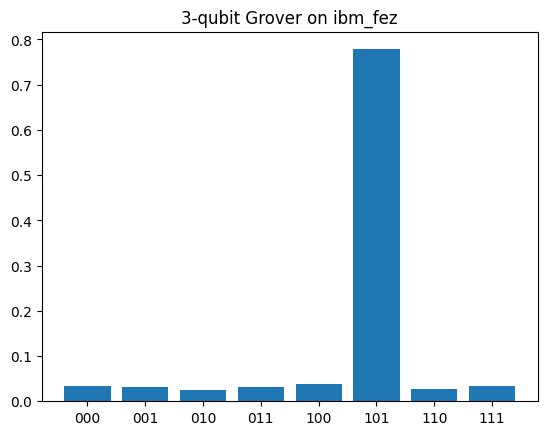

In [35]:
GOOD_3 = [144, 143, 142]  # three connected qubits with low error

# P(|101>) as a product of Pauli projectors, so it runs on the Estimator primitive
target_pauli = qml.prod((qml.I(0) - qml.Z(0)) / 2,
                        (qml.I(1) + qml.Z(1)) / 2,
                        (qml.I(2) - qml.Z(2)) / 2)

if RUN_ON_HARDWARE:
    hw3 = qml.device('qiskit.remote', wires=3, backend=backend, shots=8192,
                     initial_layout=GOOD_3, optimization_level=3)

    @qml.qnode(hw3)
    def hw3_probs():
        grover_body()
        return qml.probs(wires=WIRES)

    @qml.qnode(hw3)
    def hw3_expval():
        grover_body()
        return qml.expval(target_pauli)

    probs3 = np.array(hw3_probs())
    zne3 = float(mitigate_with_zne(hw3_expval, [1, 2, 3], fold_global,
                                   richardson_extrapolate)())

    print(f'ideal  P({TARGET}) = {ideal_p:.3f}')
    print(f'raw    P({TARGET}) = {probs3[target_idx]:.3f}')
    print(f'ZNE    P({TARGET}) = {zne3:.3f}')
    plt.bar([format(i, '03b') for i in range(8)], probs3)
    plt.title('3-qubit Grover on ibm_fez')
    plt.show()

On hardware the success probability drops from the ideal 0.945 to 0.778, so the peak at `101` survives the noise, and ZNE raises it to 0.960. The mitigated value lands slightly above the ideal one, most likely because the extrapolation also amplifies the statistical error of the noisier runs.

## References

- Assignment and report (`docs/report.pdf`), Quantum Computing course, MSc in Engineering Physics, University of Minho.
- Course materials by professors Luís Barbosa and André Sequeira.
- [PennyLane](https://pennylane.ai/).